In [1]:
# ! pip install transformers

In [1]:
import ssl
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np 
import re
import string
import nltk
from nltk.corpus import stopwords
from wordcloud import WordCloud
from nltk.stem.snowball import SnowballStemmer
import pickle
    
nltk.download('stopwords')

from pylab import rcParams
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from collections import defaultdict

# Torch ML libraries
from transformers import BertModel, BertTokenizer, AdamW, get_linear_schedule_with_warmup, RobertaModel
from torch import nn
from torch.utils.data import Dataset, DataLoader

from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')
sns.set()

# pip install boto3==1.33.13 botocore==1.33.13 awscli==1.31.13 aiobotocore==2.9.0 --ignore-installed
# pip unistall urllib3 pip install urllib3

[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/rabiya/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2025-02-20 22:43:48.365356: I tensorflow/core/platform/cpu_feature_guard.cc:182] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import torch
# Set intial variables and constants
%config InlineBackend.figure_format='retina'

RANDOM_SEED = 1
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cpu


In [5]:
data = pd.read_csv('files/train.csv', encoding='latin-1')
data.head()

,id,comment_text,toxic,severe_toxic,obscene,threat,insult,identity_hate
0,0000997932d777bf,Explanation\nWhy the edits made under my usern...,0,0,0,0,0,0
1,000103f0d9cfb60f,D'aww! He matches this background colour I'm s...,0,0,0,0,0,0
2,000113f07ec002fd,"Hey man, I'm really not trying to edit war. It...",0,0,0,0,0,0
3,0001b41b1c6bb37e,"""\nMore\nI can't make any real suggestions on ...",0,0,0,0,0,0
4,0001d958c54c6e35,"You, sir, are my hero. Any chance you remember...",0,0,0,0,0,0


In [5]:
data['class'] = data[['toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate']].sum(axis=1)
category_names = {
    0: 'No Toxicity',
    1: 'Toxic',
    2: 'Severe Toxic',
    3: 'Obscene',
    4: 'Threat',
    5: 'Insult',
    6: 'Identity Hate'
}

# Replace numeric values with category names
data['class'] = data['class'].map(category_names)

# Drop the individual class columns
data.drop(columns=['id','toxic', 'severe_toxic', 'obscene', 'threat', 'insult', 'identity_hate'], inplace=True)

data

,comment_text,class
0,Explanation\nWhy the edits made under my usern...,No Toxicity
1,D'aww! He matches this background colour I'm s...,No Toxicity
2,"Hey man, I'm really not trying to edit war. It...",No Toxicity
3,"""\nMore\nI can't make any real suggestions on ...",No Toxicity
4,"You, sir, are my hero. Any chance you remember...",No Toxicity
...,...,...
159566,""":::::And for the second time of asking, when ...",No Toxicity
159567,You should be ashamed of yourself \n\nThat is ...,No Toxicity
159568,"Spitzer \n\nUmm, theres no actual article for ...",No Toxicity
159569,And it looks like it was actually you who put ...,No Toxicity


In [6]:
data['class'].value_counts()

No Toxicity      143346
Toxic              6360
Obscene            4209
Severe Toxic       3480
Threat             1760
Insult              385
Identity Hate        31
Name: class, dtype: int64

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   comment_text  159571 non-null  object
 1   class         159571 non-null  object
dtypes: object(2)
memory usage: 2.4+ MB


In [8]:
#Drop Nan Value rows
data.dropna(inplace=True)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 159571 entries, 0 to 159570
Data columns (total 2 columns):
 #   Column        Non-Null Count   Dtype 
---  ------        --------------   ----- 
 0   comment_text  159571 non-null  object
 1   class         159571 non-null  object
dtypes: object(2)
memory usage: 2.4+ MB


In [9]:
from sklearn.preprocessing import LabelEncoder
LE = LabelEncoder()

data['class'] = LE.fit_transform(data['class'])

data['class'].value_counts()

2    143346
6      6360
3      4209
4      3480
5      1760
1       385
0        31
Name: class, dtype: int64

In [10]:
#function to clean text
def  clean_text(text):
    text =  text.lower()
    text = re.sub(r"i'm", "i am", text)
    text = re.sub(r"\r", "", text)
    text = re.sub(r"he's", "he is", text)
    text = re.sub(r"she's", "she is", text)
    text = re.sub(r"it's", "it is", text)
    text = re.sub(r"that's", "that is", text)
    text = re.sub(r"what's", "that is", text)
    text = re.sub(r"where's", "where is", text)
    text = re.sub(r"how's", "how is", text)
    text = re.sub(r"\'ll", " will", text)
    text = re.sub(r"\'ve", " have", text)
    text = re.sub(r"\'re", " are", text)
    text = re.sub(r"\'d", " would", text)
    text = re.sub(r"\'re", " are", text)
    text = re.sub(r"won't", "will not", text)
    text = re.sub(r"can't", "cannot", text)
    text = re.sub(r"n't", " not", text)
    text = re.sub(r"n'", "ng", text)
    text = re.sub(r"'bout", "about", text)
    text = re.sub(r"'til", "until", text)
    text = re.sub(r"[-()\"#/@;:<>{}`+=~|.!?,]", "", text)
    text = text.translate(str.maketrans('', '', string.punctuation)) 
    text = re.sub("(\\W)"," ",text) 
    text = re.sub('\S*\d\S*\s*','', text)
    
    return text

In [11]:
data.comment_text = data.comment_text.apply(clean_text)

In [14]:
sn = SnowballStemmer(language='english')

def stemmer(text):
    words =  text.split()
    train = [sn.stem(word) for word in words if not word in set(stopwords.words('english'))]
    return ' '.join(train)

In [ ]:
data.comment_text = data.comment_text.apply(stemmer)

data.to_csv("files/Updated_data.csv")


In [3]:
data = pd.read_csv("files/Updated_data.csv")
data.drop(columns='Unnamed: 0',inplace=True)
data.dropna(inplace=True)
data = data.head(50000)
data

,comment_text,class
0,explan edit made usernam hardcor metallica fan...,2
1,daww match background colour seem stuck thank ...,2
2,hey man realli tri edit war guy constant remov...,2
3,cannot make real suggest improv wonder section...,2
4,sir hero chanc rememb page,2
...,...,...
50022,know tri frame fake inform get unless think guess,2
50023,die though ok dont worri,2
50024,redirect talkjosã da silva canoeist,2
50025,subject sister wrote letter editor post gazett...,2


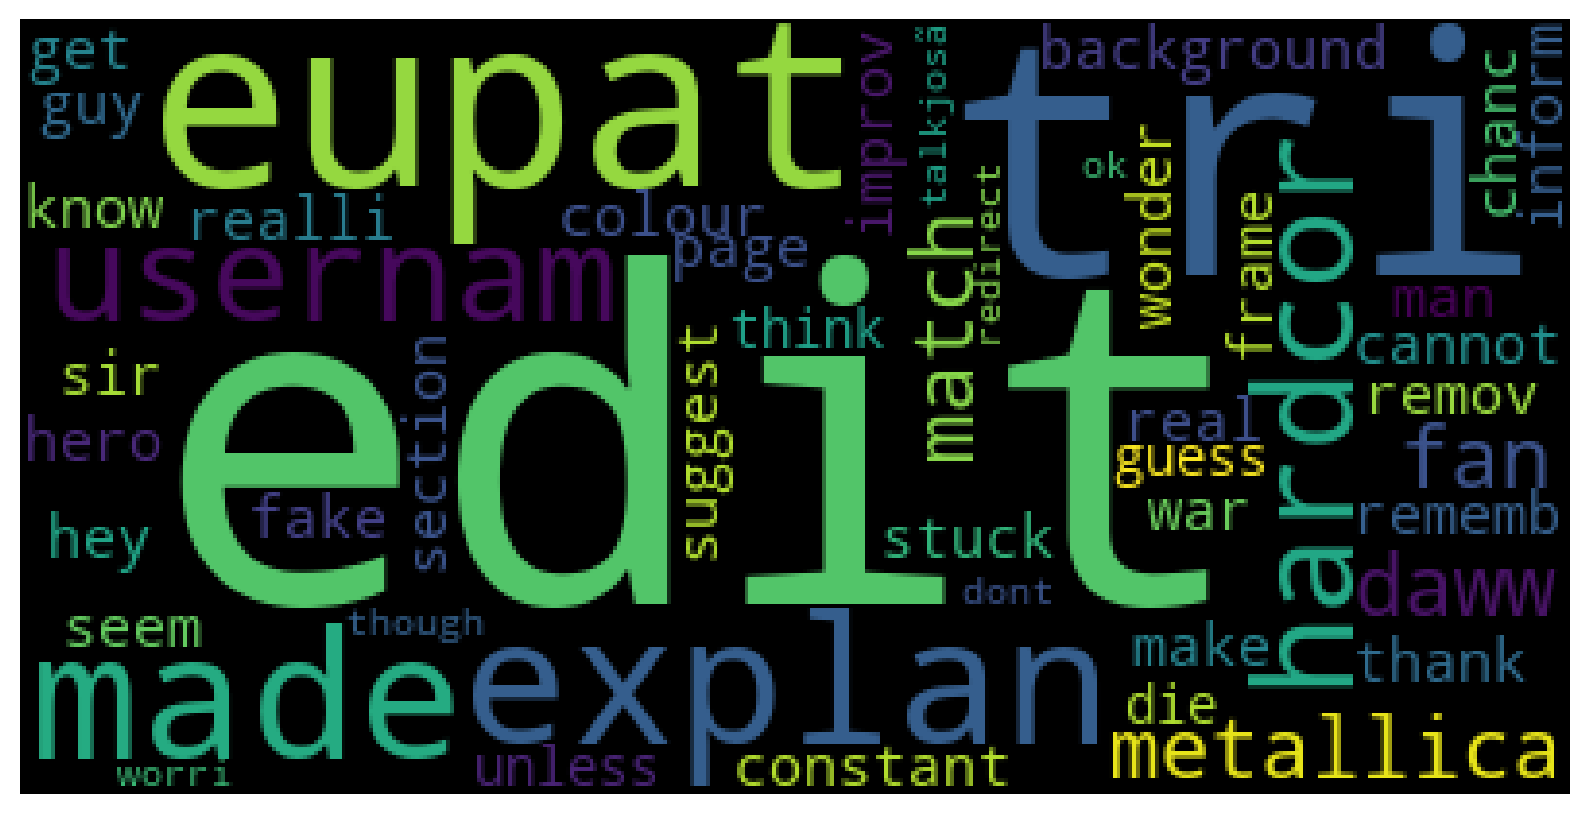

In [4]:
wordcloud = WordCloud(stopwords=stopwords.words('english'),max_words=50).generate(str(data.comment_text))
plt.figure(figsize=(10,6))
plt.imshow(wordcloud)
plt.axis('off')
plt.show()

In [5]:
x =  data.drop(columns=["class"])
y =  data['class']
x.head()

,comment_text
0,explan edit made usernam hardcor metallica fan...
1,daww match background colour seem stuck thank ...
2,hey man realli tri edit war guy constant remov...
3,cannot make real suggest improv wonder section...
4,sir hero chanc rememb page


In [3]:
# Set the model name
MODEL_NAME = 'bert-base-cased'

# Build a BERT based tokenizer
bert_tokenizer = BertTokenizer.from_pretrained(MODEL_NAME)

print(bert_tokenizer.pad_token)  # Should print '[PAD]'

[PAD]


In [5]:
dir(bert_tokenizer)  # List all attributes

['SPECIAL_TOKENS_ATTRIBUTES',
 '__annotations__',
 '__call__',
 '__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__len__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_add_tokens',
 '_additional_special_tokens',
 '_auto_class',
 '_batch_encode_plus',
 '_batch_prepare_for_model',
 '_bos_token',
 '_call_one',
 '_cls_token',
 '_convert_id_to_token',
 '_convert_token_to_id',
 '_convert_token_to_id_with_added_voc',
 '_create_repo',
 '_create_trie',
 '_decode',
 '_decode_use_source_tokenizer',
 '_encode_plus',
 '_eos_token',
 '_eventual_warn_about_too_long_sequence',
 '_eventually_correct_t5_max_length',
 '_from_pretrained',
 '_get_files_timestamps',
 '_get_padding_truncation_strategies',
 '_in_target_context_manager

In [7]:
# Store length of each review 
token_lens = []

# Iterate through the content slide
for txt in data.comment_text:
    tokens = bert_tokenizer.encode(txt, truncation=True, max_length=512)
    token_lens.append(len(tokens))

Text(0.5, 0, 'Token count')

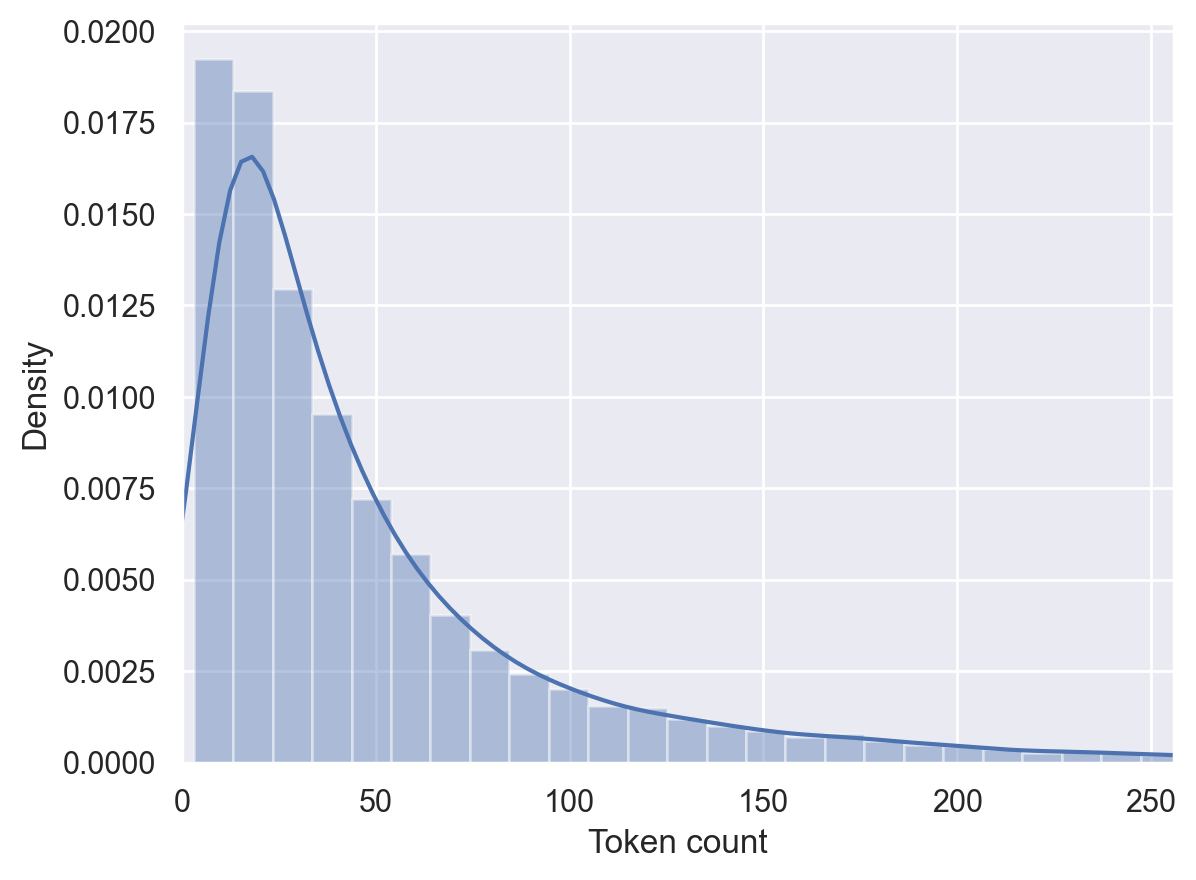

In [8]:
#Distribution Plot
sns.distplot(token_lens)
plt.xlim([0, 256])
plt.xlabel('Token count')

In [9]:
#Max Length for Sentences
MAX_LEN = 130

In [10]:
class Loading_Dataset(Dataset):
    # Constructor Function 
    def __init__(self, reviews, targets, bert_tokenizer, max_len):
        self.reviews = reviews
        self.targets = targets
        self.tokenizer = bert_tokenizer
        self.max_len = max_len
    
    def __len__(self):
        return len(self.reviews)
    
    # get item magic method
    def __getitem__(self, item):
        review = str(self.reviews[item])
        target = self.targets[item]
        
        # Encoded format to be returned 
        encoding = self.tokenizer.encode_plus( review, add_special_tokens=True, max_length=self.max_len,
            return_token_type_ids=False, pad_to_max_length=True, return_attention_mask=True, return_tensors='pt')
        
        return {
            'tweet_text': review,
            'inp_ids': encoding['input_ids'].flatten(),
            'att_mask': encoding['attention_mask'].flatten(),
            'targets': torch.tensor(target, dtype=torch.long)
        }

In [11]:
df_train, df_test = train_test_split(data, test_size=0.2, random_state=RANDOM_SEED)
df_val, df_test = train_test_split(df_test, test_size=0.5, random_state=RANDOM_SEED)

print(df_train.shape, df_val.shape, df_test.shape)

(40000, 2) (5000, 2) (5000, 2)


In [12]:
def data_loader(data, bert_tokenizer, max_len, batch_size):
    ds = Loading_Dataset( reviews=data.comment_text.to_numpy(), targets=data['class'].to_numpy(),
        bert_tokenizer=bert_tokenizer, max_len=max_len)
    
    return DataLoader(ds, batch_size=batch_size, num_workers=0)

In [13]:
# Create train, test and val data loaders
BATCH_SIZE = 16
train_loader = data_loader(df_train, bert_tokenizer, MAX_LEN, BATCH_SIZE)
val_loader = data_loader(df_val, bert_tokenizer, MAX_LEN, BATCH_SIZE)
test_loader = data_loader(df_test, bert_tokenizer, MAX_LEN, BATCH_SIZE)

In [14]:
# Examples 
data = next(iter(train_loader))

print(data.keys())
print(data['inp_ids'].shape)
print(data['att_mask'].shape)
print(data['targets'].shape)

Truncation was not explicitly activated but `max_length` is provided a specific value, please use `truncation=True` to explicitly truncate examples to max length. Defaulting to 'longest_first' truncation strategy. If you encode pairs of sequences (GLUE-style) with the tokenizer you can select this strategy more precisely by providing a specific strategy to `truncation`.


dict_keys(['tweet_text', 'inp_ids', 'att_mask', 'targets'])
torch.Size([16, 130])
torch.Size([16, 130])
torch.Size([16])


In [15]:
from transformers import RemBertModel, BertModel
# Load the BERT model
bert_model = BertModel.from_pretrained('bert-base-cased', return_dict=False)

In [16]:
class HateClassifier(nn.Module):
    
    # Constructor class 
    def __init__(self, n_classes, MODEL_NAME):
        super(HateClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.roberta = RobertaModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size + self.roberta.config.hidden_size, n_classes)
    
    # Forward propagation method
    def forward(self, inp_ids, att_mask):
        _, bert_pooled_output = self.bert(input_ids=inp_ids, attention_mask=att_mask)
        _, roberta_pooled_output = self.roberta(input_ids=inp_ids, attention_mask=att_mask)
        
        # Concatenate or combine the pooled outputs
        combined_output = torch.cat((bert_pooled_output, roberta_pooled_output), dim=1)
        
        # Add a dropout layer 
        output = self.drop(combined_output)
        
        # Pass through a linear layer for classification
        return self.out(output)


In [17]:
class_names = ['Identity Hate','Insult','No Toxicity','Obscene','Severe Toxic','Threat','Toxic']

In [18]:

model = HateClassifier(len(class_names),MODEL_NAME)
model = model.to(device)

You are using a model of type bert to instantiate a model of type roberta. This is not supported for all configurations of models and can yield errors.
Some weights of RobertaModel were not initialized from the model checkpoint at bert-base-cased and are newly initialized: ['embeddings.LayerNorm.bias', 'embeddings.LayerNorm.weight', 'embeddings.position_embeddings.weight', 'embeddings.token_type_embeddings.weight', 'embeddings.word_embeddings.weight', 'encoder.layer.0.attention.output.LayerNorm.bias', 'encoder.layer.0.attention.output.LayerNorm.weight', 'encoder.layer.0.attention.output.dense.bias', 'encoder.layer.0.attention.output.dense.weight', 'encoder.layer.0.attention.self.key.bias', 'encoder.layer.0.attention.self.key.weight', 'encoder.layer.0.attention.self.query.bias', 'encoder.layer.0.attention.self.query.weight', 'encoder.layer.0.attention.self.value.bias', 'encoder.layer.0.attention.self.value.weight', 'encoder.layer.0.intermediate.dense.bias', 'encoder.layer.0.intermediate

In [19]:
# Number of iterations 
EPOCHS = 5

# Optimizer Adam 
optimizer = AdamW(model.parameters(), lr=2e-5, correct_bias=False)

total_steps = len(train_loader) * EPOCHS

scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=0, num_training_steps=total_steps )

# Create the loss function 
loss_fn = nn.CrossEntropyLoss().to(device)

In [20]:
# Function for a single training iteration
def train_epoch(model, data_loader, loss_fn, optimizer, device, scheduler, n_examples):
    model = model.train()
    losses = []
    correct_predictions = 0
    
    for d in tqdm(data_loader):
        inp_ids = d["inp_ids"].to(device)
        att_mask = d["att_mask"].to(device)
        targets = d["targets"].to(device)
        
        outputs = model( inp_ids=inp_ids, att_mask=att_mask)
        
        _, preds = torch.max(outputs, dim=1)
        loss = loss_fn(outputs, targets)
        correct_predictions += torch.sum(preds == targets)
        losses.append(loss.item())
        
        # Backward prop
        loss.backward()
        
        # Gradient Descent
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        scheduler.step()
        optimizer.zero_grad()
    
    return correct_predictions.double() / n_examples, np.mean(losses)

In [21]:
def eval_model(model, data_loader, loss_fn, device, n_examples):
    model = model.eval()
    
    losses = []
    correct_predictions = 0
    
    with torch.no_grad():
        for d in tqdm(data_loader):
            inp_ids = d["inp_ids"].to(device)
            att_mask = d["att_mask"].to(device)
            targets = d["targets"].to(device)
            
            # Get model ouptuts
            outputs = model(inp_ids=inp_ids, att_mask=att_mask)
            
            _, preds = torch.max(outputs, dim=1)
            loss = loss_fn(outputs, targets)
            
            correct_predictions += torch.sum(preds == targets)
            losses.append(loss.item())
            
    return correct_predictions.double() / n_examples, np.mean(losses)

In [22]:
history = defaultdict(list)
best_accuracy = 0

print(device)

for epoch in range(EPOCHS):
    
    # Show details 
    print(f"Epoch {epoch + 1}/{EPOCHS}")
    print("-" * 10)
    
    train_acc, train_loss = train_epoch(model, train_loader, loss_fn, optimizer, device, scheduler, len(df_train))
    
    print(f"Train loss {train_loss} accuracy {train_acc}")

    # Get model performance (accuracy and loss)
    val_acc, val_loss = eval_model( model, val_loader, loss_fn, device,len(df_val))
    
    print(f"Val   loss {val_loss} accuracy {val_acc}")
    
    history['train_acc'].append(train_acc)
    history['train_loss'].append(train_loss)
    history['val_acc'].append(val_acc)
    history['val_loss'].append(val_loss)
    
    # If we beat prev performance
    if val_acc > best_accuracy:
        torch.save(model.state_dict(), 'bert/HateDetectionModel.bin')
        best_accuracy = val_acc
    
  

cuda
Epoch 1/5
----------


100%|██████████| 2500/2500 [19:56<00:00,  2.09it/s]


Train loss 0.29901353506473827 accuracy 0.9087500000000001


100%|██████████| 313/313 [00:45<00:00,  6.86it/s]


Val   loss 0.24396218853621796 accuracy 0.9174
Epoch 2/5
----------


...

Val   loss 0.2826255244032194 accuracy 0.9236000000000001
Epoch 5/5
----------


100%|██████████| 2500/2500 [19:51<00:00,  2.10it/s]


Train loss 0.15037721338132395 accuracy 0.951725


100%|██████████| 313/313 [00:45<00:00,  6.87it/s]

Val   loss 0.3006359226382397 accuracy 0.92


In [23]:
plot_history = dict()
plot_history['train_acc'] = [0,]
for i in history['train_acc']:
  plot_history['train_acc'].append(float(i))

plot_history['val_acc'] = [0,]
for i in history['val_acc']:
  plot_history['val_acc'].append(float(i))

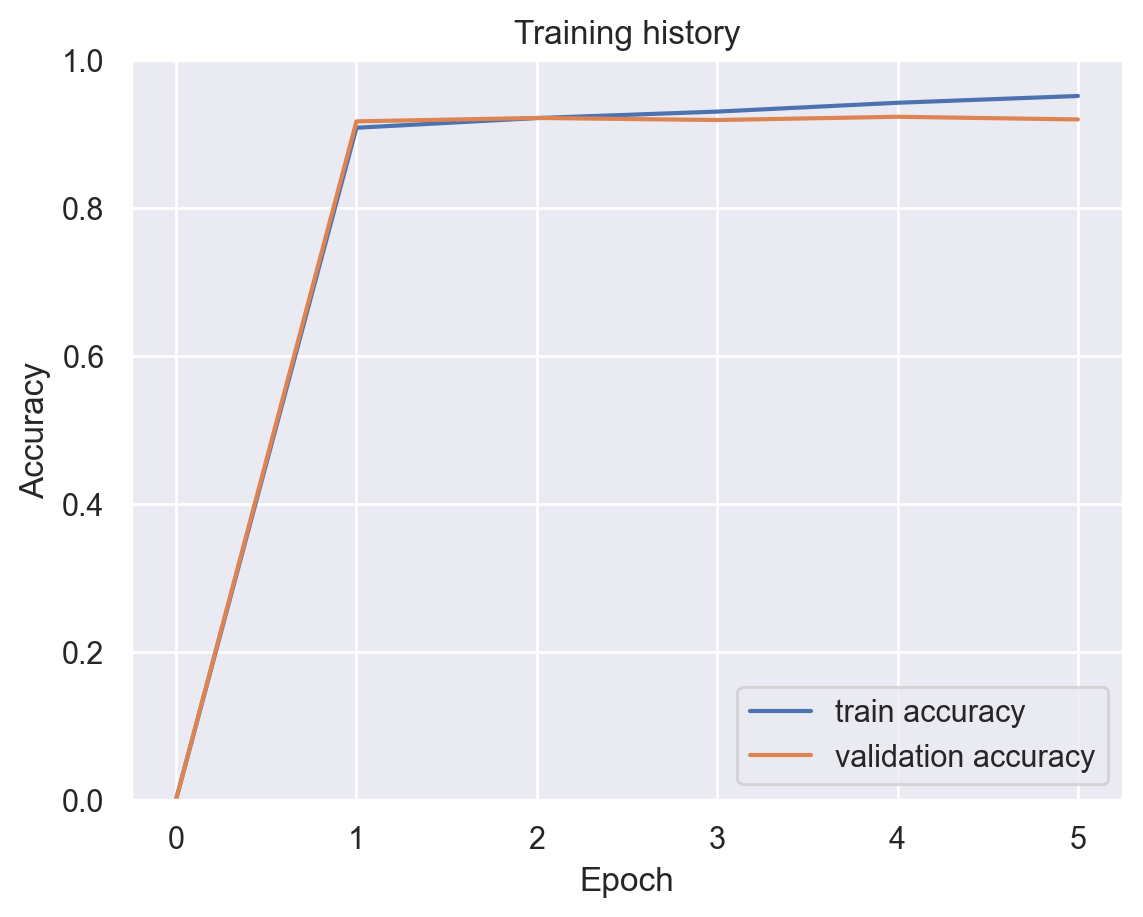

In [24]:
# Plot training and validation accuracy
plt.plot(plot_history['train_acc'], label='train accuracy')
plt.plot(plot_history['val_acc'], label='validation accuracy')

# Graph chars
plt.title('Training history')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.ylim([0, 1]);

In [25]:
train_acc, _ = eval_model(model, train_loader, loss_fn, device, len(df_train))
print()
print("Train Accuracy:",round(float(train_acc*100),2), "%")

100%|██████████| 2500/2500 [06:05<00:00,  6.84it/s]


Train Accuracy: 95.87 %


In [26]:
test_acc, _ = eval_model(model, test_loader, loss_fn, device, len(df_test))
print()
print("Test Accuracy:",round(float(test_acc*100),2), "%")

100%|██████████| 313/313 [00:45<00:00,  6.87it/s]


Test Accuracy: 90.76 %


In [27]:
text = "i wanna kill you!!!"

In [28]:
encoded_review = bert_tokenizer.encode_plus( text, max_length=MAX_LEN, add_special_tokens=True,
    return_token_type_ids=False, pad_to_max_length=True, return_attention_mask=True, return_tensors='pt')
    
inp_ids = encoded_review['input_ids'].to(device)
att_mask = encoded_review['attention_mask'].to(device)

op = model(inp_ids, att_mask)
_, pred = torch.max(op, dim=1)

print(f'Tweet text: {text}')
print(f'Predicted Sentiment  : {class_names[pred]}')

Tweet text: i wanna kill you!!!
Predicted Sentiment  : Severe Toxic


In [29]:
# pickle.dump(bert_tokenizer, open("bert/BertTokenizer.sav", 'wb'))
# pickle.dump(model, open("bert/HateDetection_model.sav", 'wb'))

In [30]:
torch.save(bert_tokenizer,r"bert/BertTokenizer.pth")
torch.save(model.state_dict(),"bert/RobertaHateDetectionModel.pth")

## Inference

In [ ]:
import pickle
import torch
import ssl
try:
    _create_unverified_https_context = ssl._create_unverified_context
except AttributeError:
    pass
else:
    ssl._create_default_https_context = _create_unverified_https_context

import seaborn as sns
import nltk
from nltk.corpus import stopwords
    
nltk.download('stopwords')

# Torch ML libraries
from transformers import BertModel, RobertaModel
from torch import nn
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings('ignore')
sns.set()

import logging
from transformers import logging as transformers_logging

# Set logging level to ERROR to suppress warnings and info messages
logging.basicConfig(level=logging.ERROR)
transformers_logging.set_verbosity_error()


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class HateClassifier(nn.Module):
    
    # Constructor class 
    def __init__(self, n_classes, MODEL_NAME):
        super(HateClassifier, self).__init__()
        self.bert = BertModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.roberta = RobertaModel.from_pretrained(MODEL_NAME, return_dict=False)
        self.drop = nn.Dropout(p=0.3)
        self.out = nn.Linear(self.bert.config.hidden_size + self.roberta.config.hidden_size, n_classes)
    
    # Forward propagation method
    def forward(self, inp_ids, att_mask):
        _, bert_pooled_output = self.bert(input_ids=inp_ids, attention_mask=att_mask)
        _, roberta_pooled_output = self.roberta(input_ids=inp_ids, attention_mask=att_mask)
        
        # Concatenate or combine the pooled outputs
        combined_output = torch.cat((bert_pooled_output, roberta_pooled_output), dim=1)
        
        # Add a dropout layer 
        output = self.drop(combined_output)
        
        # Pass through a linear layer for classification
        return self.out(output)

def prediction_model(text):


    MAX_LEN = 130

    MODEL_NAME = 'bert-base-cased'

    class_names = ['Identity Hate','Insult','No Toxicity','Obscene','Severe Toxic','Threat','Toxic']

    #Loading Saved Models
    bert_tokenizer = torch.load(r"bert/BertTokenizer.pth")
    loaded_model = HateClassifier(len(class_names), MODEL_NAME).to(device)
    loaded_model.load_state_dict(torch.load(r"bert/RobertaHateDetectionModel.pth", map_location=device))

        # Explicitly setting pad_token if it's missing
    if bert_tokenizer.pad_token is None:
        bert_tokenizer.pad_token = bert_tokenizer.eos_token or "[PAD]"

    encoded_review = bert_tokenizer.encode_plus( text, max_length=MAX_LEN, add_special_tokens=True,
        return_token_type_ids=False,  padding="max_length", pad_to_max_length=True, return_attention_mask=True, return_tensors='pt')
        
    inp_ids = encoded_review['input_ids'].to(device)
    att_mask = encoded_review['attention_mask'].to(device)

    op = loaded_model(inp_ids, att_mask)
    _, pred = torch.max(op, dim=1)

    print(f'Given text: {text}')
    print(f'Detected sentiment  : {class_names[pred]}')

    return class_names[pred]

prediction_model("everything in the world is awesome!!!")
# pip install --upgrade pip setuptools wheel


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\91997\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [34]:
prediction_model("you are ugly!!!")

Given text: you are ugly!!!
Detected sentiment  : Severe Toxic


'Severe Toxic'

In [35]:
prediction_model("i hate you as a person!!!")

Given text: i hate you as a person!!!
Detected sentiment  : Toxic


'Toxic'

In [36]:
prediction_model("i wanna kill you!!!!")

Given text: i wanna kill you!!!!
Detected sentiment  : Severe Toxic


'Severe Toxic'

In [37]:
prediction_model("i love myself!!!!")

Given text: i love myself!!!!
Detected sentiment  : No Toxicity


'No Toxicity'

In [38]:
prediction_model("she is a pathetic")

Given text: she is a pathetic
Detected sentiment  : Obscene


'Obscene'